# Homework — Group 34
## Repeat Purchase Prediction (Everything & Then Some)

Predict whether a customer buys again within 90 days of a purchase (`repeat_purchase_90d`) and generate predictions for every row of `test.csv`.

1. **Import and explore the data**: tables, data quality, missing and impossible values, train vs test, relationships with the target;
2. **Clean and pre-process**: fixed repair rules, validation design, numeric treatment, encoding and scaling, new features and `clientes.csv`;
3. **Feature selection**: filter, wrapper and embedded methods, combined by a vote;
4. **Build a simple model and assess performance**: logistic regression, decision threshold for F1, time-ordered check;
5. **Predictions for `test.csv`**: final model fitted on all training rows, submission file.

The data files (`train.csv`, `test.csv`, `clientes.csv`, `sample_submission.csv`) are read from the `data` folder next to this notebook.

# <font color='#E8800A'>1. Import and explore the data</font> <a class="anchor" id="explore"></a>

1: Import the libraries and fix the random seed.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")

from sklearn.metrics import f1_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
FIGSIZE = (6, 5)
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"

TARGET = "repeat_purchase_90d"

DATA_DIR = Path("data")  # Folder that holds the four CSV files

warnings.filterwarnings("ignore", category=FutureWarning)

2: Load the tables and check if they fit together.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["purchase_date"]).set_index("ID")
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["purchase_date"]).set_index("ID")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

for name, frame in [("train", train), ("test", test), ("clientes", clientes)]:
    print(f"{name:9s} {frame.shape[0]:>5,} rows x {frame.shape[1]} columns")

print("\ntest IDs match sample_submission:", sample["ID"].tolist() == test.index.tolist())
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

train     6,534 rows x 38 columns
test        986 rows x 37 columns
clientes  1,143 rows x 13 columns

test IDs match sample_submission: True
columns only in train: ['repeat_purchase_90d']


<div class="alert alert-block alert-warning">

- Train has 6,534 rows;
- Test has 986 (about 15% of the size of train);
- Test IDs match the submission template in the same order, and the target is the only column missing from test.

</div>

3: Separate the column roles and look at the target.

In [3]:
categorical = train.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = [c for c in train.select_dtypes(include="number").columns if c != TARGET]

print(f"{len(numeric)} numeric columns:\n  {numeric}\n")
print(f"{len(categorical)} categorical columns:\n  {categorical}\n")

print(train[TARGET].value_counts()
      .to_frame("rows")
      .assign(share=lambda d: (d["rows"] / d["rows"].sum()).round(4)))

always_repeat = np.ones(len(train), dtype=int)
print(f"\nF1 of predicting 'repeat' for every row: {f1_score(train[TARGET], always_repeat):.4f}")

30 numeric columns:
  ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'random_noise']

6 categorical columns:
  ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']

                     rows   share
repeat_purchase_90d              
1                    3654  0.5592
0                    2880  0.4408

F1 of predicting 'repeat' for every row: 0.7173


<div class="alert alert-block alert-warning">

- 30 columns are stored as numbers;
- 6 columns are stored as text;
- 2 numeric columns are not quantities (`customer_id` and `random_noise`);
- The target is mildly imbalanced: 55.9% repeat, 44.1% not;
- F1 on the positive class, answering "repeat" for every row
  already scores F1 0.717.
  
</div>

4: Look at descriptive statistics.

In [4]:
print(train[numeric].describe().T.round(2).to_string())
print()
print(train[categorical].describe().T.to_string())

                                 count        mean          std        min        25%        50%        75%           max
Total a Pagar                   6469.0      925.56      1335.00       0.93     188.92     476.74    1087.67  2.229721e+04
Total Bruto                     6469.0      886.15      1327.64       0.83     175.74     445.74    1036.70  2.157828e+04
Total Liquido                   6469.0      773.34      1136.36       0.76     154.38     389.91     903.37  1.812781e+04
Total Imp_                      6469.0      152.22       225.26       0.00      29.93      79.74     184.84  4.169400e+03
Total Portes                    6469.0        1.15         5.84       0.00       0.00       0.00       0.00  1.810600e+02
Total Desc_ Global              6469.0        0.35         5.12       0.00       0.00       0.00       0.00  2.184900e+02
Total Desc_ Linha               6469.0      112.47       289.99       0.00       0.00      13.13      92.28  4.103440e+03
Custo                   

<div class="alert alert-block alert-warning">

- Most columns have 6,469 values instead of 6,534;
- 65 rows are missing almost everything;
- Means far above medians (e.g. `Total a Pagar` 926 vs 477, `prior_total_spend` 18,908 vs 6,754) indicate strong right skew in money columns;
- Impossible extremes: `prior_mean_purchase_value` reaches 1e9 and goes negative, and day counts reach -4;
- A handful of such values inflate the mean of `prior_mean_purchase_value` to 2.8 million while its median stays at 725;
- Near-constant columns: `Total Portes` and `Total Desc_ Global` are 0 in over 75% of rows, `invoice_count_current_purchase` is almost always 1, `commercial_zone` has one level in 97% of rows and `warehouse` one level in 99.7%. They are likely to carry little information;
- `transport_method` has 80 levels, many of them rare.

</div>

5: Look at missing values, in train and test side by side.

In [5]:
missing = (pd.DataFrame({"train gaps": train.isna().sum(),
                         "train %": (train.isna().mean() * 100).round(2),
                         "test gaps": test.isna().sum(),
                         "test %": (test.isna().mean() * 100).round(2),})
           .query("`train gaps` > 0")
           .sort_values("train gaps", ascending=False))
print(missing.to_string())

gaps_per_row_train = train.isna().sum(axis=1)
print("\nrows by number of  train gaps:")
print(gaps_per_row_train.value_counts().sort_index().to_string())

gaps_per_row_test = test.isna().sum(axis=1)
print("\nrows by number of  test gaps:")
print(gaps_per_row_test.value_counts().sort_index().to_string())

                                train gaps  train %  test gaps  test %
prior_std_gap_days                    1478    22.62       69.0    7.00
prior_mean_gap_days                   1308    20.02       76.0    7.71
prior_std_purchase_value              1113    17.03       46.0    4.67
prior_mean_purchase_value              862    13.19       52.0    5.27
days_since_previous_purchase           861    13.18       52.0    5.27
prior_min_purchase_value               668    10.22       22.0    2.23
prior_max_purchase_value               668    10.22       22.0    2.23
transport_method                       261     3.99       30.0    3.04
spend_365d                             260     3.98       30.0    3.04
payment_type                           260     3.98       30.0    3.04
warehouse                              260     3.98       30.0    3.04
salesperson                            259     3.96       30.0    3.04
customer_tenure_days                    65     0.99        0.0    0.00
purcha

In [6]:
empty_rows = gaps_per_row_train >= train.shape[1] - 5
print(f"{empty_rows.sum()} nearly empty rows")
print("columns still filled in them:",
      train.loc[empty_rows].notna().sum()[lambda s: s > 0].to_dict())

print(f"\nduplicated rows (extra copies): {train.duplicated().sum()}")
print(f"rows involved in a duplication: {train.duplicated(keep=False).sum()}")

filled = train.loc[~empty_rows]
print(f"duplicates once the empty rows are set aside:", filled.duplicated().sum())

65 nearly empty rows
columns still filled in them: {'repeat_purchase_90d': 65, 'customer_id': 65}

duplicated rows (extra copies): 10
rows involved in a duplication: 16
duplicates once the empty rows are set aside: 0


<div class="alert alert-block alert-warning">

- 65 rows are empty records, and they explain the duplicates. They keep only `customer_id` and the `target`; every one of the 36 other columns is missing;
- The test file has no such row: every column with exactly 65 gaps in train has 0 gaps in test;
- The 10 "duplicates" are these same empty rows.

</div>

6: Test if the remaining gaps are not all of one kind.

In [7]:
history = (filled["prior_purchase_count"].clip(upper=3).astype(int)
           .map({0: "0", 1: "1", 2: "2", 3: "3+"}))
prior_cols = ["days_since_previous_purchase", "prior_mean_purchase_value",
              "prior_min_purchase_value", "prior_max_purchase_value",
              "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

print("\n% missing by number of previous purchases:")
print(filled[prior_cols].isna().groupby(history).mean().mul(100).round(1).T.to_string())

print("\nrepeat rate by number of previous purchases:")
print(filled.groupby(history)[TARGET].agg(rows="size", repeat_rate="mean").round(3).to_string())


% missing by number of previous purchases:
prior_purchase_count              0      1      2   3+
days_since_previous_purchase  100.0    4.3    5.5  3.0
prior_mean_purchase_value     100.0    4.5    3.0  3.2
prior_min_purchase_value      100.0    0.0    0.0  0.0
prior_max_purchase_value      100.0    0.0    0.0  0.0
prior_std_purchase_value      100.0  100.0    0.0  0.0
prior_mean_gap_days           100.0  100.0    5.8  3.4
prior_std_gap_days            100.0  100.0  100.0  0.0

repeat rate by number of previous purchases:
                      rows  repeat_rate
prior_purchase_count                   
0                      603        0.333
1                      445        0.373
2                      365        0.400
3+                    5056        0.615


<div class="alert alert-block alert-warning">

- We find three kinds of missing values:

1. Structural: With 0 previous purchases every `prior_*` column is 100% missing; with 1, the standard deviations are 100% missing; with 2, the standard deviation of the gaps is 100% missing;
`prior_purchase_count` stays, and history flags (e.g. `has_history = prior_purchase_count > 0`) are derived by a fixed rule, which learns nothing from the data and can therefore be applied to train and test alike;
The history is predictive: first-time buyers repeat 33% of the time, customers with 3+ purchases 62%.
2. Random: 3-5% of rows with enough history still miss `days_since_previous_purchase`, `prior_mean_purchase_value` or `prior_mean_gap_days`. These are genuinely unknown and are imputed;
Some can be recomputed exactly, e.g. `prior_mean = prior_total_spend / prior_purchase_count`;
3. A ~4% block in `spend_365d`, `payment_type`, `salesperson`, `transport_method` and `warehouse`, present in test too (30 rows each).

</div>

7: Look at implausible values.

In [8]:
for column in [c for c in numeric if c != "random_noise"]:
    flags = {split: {"== 1e9": int((frame[column] >= 1e9).sum()),
                     "< 0": int((frame[column] < 0).sum())}
             for split, frame in [("train", train), ("test", test)]}
    if any(flags["train"].values()):
        print(f"{column:30s} train {flags['train']}  test {flags['test']}")

days_since_previous_purchase   train {'== 1e9': 0, '< 0': 16}  test {'== 1e9': 0, '< 0': 2}
prior_mean_purchase_value      train {'== 1e9': 16, '< 0': 16}  test {'== 1e9': 2, '< 0': 2}
prior_mean_gap_days            train {'== 1e9': 0, '< 0': 16}  test {'== 1e9': 0, '< 0': 2}
spend_365d                     train {'== 1e9': 15, '< 0': 15}  test {'== 1e9': 2, '< 0': 2}


8: Check the internal consistency of the columns.

In [9]:
f = filled
has_mean = f["prior_mean_purchase_value"].notna() & (f["prior_purchase_count"] > 0)
has_365 = f["spend_365d"].notna()
has_prev = f["days_since_previous_purchase"].notna()

checks = {
    "prior_mean = prior_total_spend / prior_purchase_count":
        np.isclose(f.loc[has_mean, "prior_mean_purchase_value"],
                   f.loc[has_mean, "prior_total_spend"] / f.loc[has_mean, "prior_purchase_count"],
                   atol=0.05).mean(),

    "prior_min <= prior_mean <= prior_max":
        ((f["prior_min_purchase_value"] <= f["prior_mean_purchase_value"] + 0.01)
         & (f["prior_mean_purchase_value"] <= f["prior_max_purchase_value"] + 0.01))[has_mean].mean(),

    "prior_max <= prior_total_spend":
        (f["prior_max_purchase_value"] <= f["prior_total_spend"] + 0.01)[f["prior_max_purchase_value"].notna()].mean(),
    "purchase counts nested (30d <= 90d <= 180d <= 365d)":
        ((f["purchase_count_30d"] <= f["purchase_count_90d"])
         & (f["purchase_count_90d"] <= f["purchase_count_180d"])
         & (f["purchase_count_180d"] <= f["purchase_count_365d"])).mean(),
    "spend nested (30d <= 90d <= 180d <= 365d)":
        ((f["spend_30d"] <= f["spend_90d"] + 0.01)
         & (f["spend_90d"] <= f["spend_180d"] + 0.01)
         & (f["spend_180d"] <= f["spend_365d"] + 0.01))[has_365].mean(),
    "customer_tenure_days >= days_since_previous_purchase":
        (f["customer_tenure_days"] >= f["days_since_previous_purchase"])[has_prev].mean(),
    "Total a Pagar = Liquido + Imp + Portes":
        np.isclose(f["Total a Pagar"],
                   f["Total Liquido"] + f["Total Imp_"] + f["Total Portes"], atol=0.05).mean(),
}
for rule, share in checks.items():
    print(f"{share:7.1%}  {rule}")

  98.6%  prior_mean = prior_total_spend / prior_purchase_count
  98.6%  prior_min <= prior_mean <= prior_max
  99.2%  prior_max <= prior_total_spend
 100.0%  purchase counts nested (30d <= 90d <= 180d <= 365d)
  99.8%  spend nested (30d <= 90d <= 180d <= 365d)
 100.0%  customer_tenure_days >= days_since_previous_purchase
  83.7%  Total a Pagar = Liquido + Imp + Portes


<div class="alert alert-block alert-warning">

- The count windows are well nested (100%) and tenure always covers the days since the previous purchase (100%), so these columns are reliable;
- `prior_mean = prior_total_spend / prior_purchase_count` fails in 1.4% of rows (78). Only 32 of them are the 1e9 and negative; the other 46 are means inflated;
- `prior_max <= prior_total_spend` fails in 0.8% of rows (45): a single previous purchase larger than the sum of all previous purchases, which is impossible;
- `prior_min <= prior_mean <= prior_max` fails in 1.4%, the same corrupted rows. Spend nesting fails in 0.2%: the negative and 1e9 values of `spend_365d`;
- `Total a Pagar = Liquido + Imp + Portes` holds in only 83.7% of rows. Probably this is not an error that can be corrected (the amounts may include other charges).

</div>

9: Find Identifier-like columns.

In [10]:
print("ID unique per row:", train.index.is_unique)
print("distinct customers in train:", filled["customer_id"].nunique())

print("\ncorrelation with the target:")
print(filled[["customer_id", "random_noise"]].corrwith(filled[TARGET]).round(4).to_string())

print("\nrows per customer:")
print(filled.groupby("customer_id").size().describe().round(1).to_string())

ID unique per row: True
distinct customers in train: 607

correlation with the target:
customer_id    -0.1112
random_noise   -0.0120

rows per customer:
count    607.0
mean      10.7
std       19.8
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      276.0


10: Compare train with test.

In [11]:
print("purchase dates")
print(pd.DataFrame({"train": train["purchase_date"].agg(["min", "max"]),
                    "test": test["purchase_date"].agg(["min", "max"])}).to_string())

seen = test["customer_id"].isin(train["customer_id"])
print(f"\ntest rows whose customer also appears in train: {seen.mean():.1%}")
print(f"test customers: {test['customer_id'].nunique()},"
      f" of which seen in train: {test.loc[seen, 'customer_id'].nunique()}")

print("\nlevels in test that never occur in train:")
for column in categorical:
    unseen = sorted(set(test[column].dropna()) - set(train[column].dropna()))
    if unseen:
        print(f"  {column}: {unseen}")

purchase dates
         train       test
min 2015-07-11 2025-05-24
max 2025-02-15 2026-10-06

test rows whose customer also appears in train: 94.5%
test customers: 206, of which seen in train: 184

levels in test that never occur in train:
  payment_type: ['Maybe Tomorrow Payment 1', 'Maybe Tomorrow Payment 5', 'Maybe Tomorrow Payment 6']
  commercial_zone: ['Decorative Dashboard Zone 1', 'Decorative Dashboard Zone 5']
  transport_method: ['Maybe Tomorrow Delivery 54', 'Maybe Tomorrow Delivery 65']
  warehouse: ['Final Excel Warehouse 2']


<div class="alert alert-block alert-warning">

- Test is later in time. Train runs from July 2015 to February 2025; test from May 2025 to October 2026. The task is to predict the future from the past;
- Customers repeat. Each customer has on average 10.7 training rows (median 4, maximum 276), and 94.5% of test rows belong to customers already seen in train (184 of 206);
- We have to be aware, in validation, a random split places rows of the same customer and of the same period in both training and validation folds, and ignores that test lies after train, so its score may be optimistic;
- `purchase_date` is not used as a raw feature. Every test date lies after the last training date, so a model would have to extrapolate on it;
- Unseen levels. `payment_type`, `commercial_zone`, `transport_method` and `warehouse` have levels in test that never occur in train. The encoder must ignore unknown levels instead of failing;
- `customer_id` and `random_noise` are excluded;
- `customer_id` correlates with the target (-0.11) only through how numbers were assigned.

</div>

11: Look into the table `clientes.csv`.

In [12]:
print("every train customer is in clientes:",
      set(train["customer_id"]) <= set(clientes["customer_id"]))
print("every test customer is in clientes: ",
      set(test["customer_id"]) <= set(clientes["customer_id"]))
print("customer_id unique in clientes:     ", clientes["customer_id"].is_unique)

profile = pd.DataFrame({"% missing": clientes.isna().mean().mul(100).round(1),
                        "unique values": clientes.nunique(),
                        "example": clientes.iloc[0]})
print()
print(profile.to_string())

every train customer is in clientes: True
every test customer is in clientes:  True
customer_id unique in clientes:      True

                     % missing  unique values                                  example
customer_id                0.0           1143                                   842570
country_or_region          0.0             11  Country CT11: Land of The Final Version
commercial_region         10.0             37           Region RG37: We Will See Later
island                    50.6             10                                      NaN
municipality              13.9            183                                      NaN
city                      47.8            417            City CY417: Missing Cell Port
postal_area                6.2            271                                      NaN
postal_code               14.9            828  Postal code PC828: #REF! Delivery Route
street                    52.3            511                                      NaN
add

<div class="alert alert-block alert-warning">

- The join is safe: every customer in train and test is present and the key is unique;
- `customer_type` is 100% empty;
- `company_name` (1,141 values) and `address` (1,120) have essentially one value per customer;
- `island`, `city` and `street` are about 50% empty;
- `postal_code` and `municipality` are high-cardinality;
- Only a few low-cardinality, well-filled columns are worth testing: `country_or_region`, `commercial_region` and `customer_since_year`.

</div>

12: Find whether the impossible values are concentrated in a few broken rows or spread out.

In [13]:
anomalies = pd.DataFrame({
    "days_since_prev < 0":    filled["days_since_previous_purchase"] < 0,
    "prior_mean_gap < 0":     filled["prior_mean_gap_days"] < 0,
    "prior_mean_value < 0":   filled["prior_mean_purchase_value"] < 0,
    "prior_mean_value = 1e9": filled["prior_mean_purchase_value"] >= 1e9,
    "spend_365d < 0":         filled["spend_365d"] < 0,
    "spend_365d = 1e9":       filled["spend_365d"] >= 1e9,
    "prior_mean_value inflated": (filled["prior_mean_purchase_value"].between(0, 1e9, inclusive="neither")
                                  & (filled["prior_mean_purchase_value"]
                                     > 2 * filled["prior_total_spend"] / filled["prior_purchase_count"])),
    "prior_max > prior_total":   filled["prior_max_purchase_value"] > filled["prior_total_spend"] + 0.01,
})
print(anomalies.sum().to_string())
print("\nrows with at least one anomaly:", anomalies.any(axis=1).sum())
print("rows with two or more:          ", (anomalies.sum(axis=1) >= 2).sum())

print("\ndistinct negative values of days_since_previous_purchase:",
      sorted(filled.loc[anomalies["days_since_prev < 0"], "days_since_previous_purchase"].unique()))

print("rows where spend_365d < 0 while spend_180d >= 0:",
      ((filled["spend_365d"] < 0) & (filled["spend_180d"] >= 0)).sum())

# How far off are the inflated means? Real values are stored with 2 decimals.
inflated = filled.loc[anomalies["prior_mean_value inflated"]]
ratio = inflated["prior_mean_purchase_value"] / (inflated["prior_total_spend"] / inflated["prior_purchase_count"])
print("\ninflated means, ratio to total / count:", ratio.describe()[["min", "50%", "max"]].round(1).to_dict())
print(inflated[["prior_mean_purchase_value", "prior_total_spend", "prior_purchase_count"]].head(3))

t = test
test_flags = {
    "prior_mean_value inflated": (t["prior_mean_purchase_value"].between(0, 1e9, inclusive="neither")
                                  & (t["prior_mean_purchase_value"]
                                     > 2 * t["prior_total_spend"] / t["prior_purchase_count"])).sum(),
    "prior_max > prior_total": (t["prior_max_purchase_value"] > t["prior_total_spend"] + 0.01).sum(),
}
print("\nsame outliers in test:", {k: int(v) for k, v in test_flags.items()})

days_since_prev < 0          16
prior_mean_gap < 0           16
prior_mean_value < 0         16
prior_mean_value = 1e9       16
spend_365d < 0               15
spend_365d = 1e9             15
prior_mean_value inflated    46
prior_max > prior_total      45

rows with at least one anomaly: 184
rows with two or more:           1

distinct negative values of days_since_previous_purchase: [np.float64(-4.0)]
rows where spend_365d < 0 while spend_180d >= 0: 15

inflated means, ratio to total / count: {'min': 8.5, '50%': 16.1, 'max': 24.8}
          prior_mean_purchase_value  prior_total_spend  prior_purchase_count
ID                                                                          
10000556               13325.783819           11589.56                   9.0
10000712               11142.309979            7390.05                  16.0
10000733               11047.015485          150673.10                 173.0

same outliers in test: {'prior_mean_value inflated': 7, 'prior_max > prior_t

<div class="alert alert-block alert-warning">

The impossible values are isolated, injected errors. 184 rows (2.8%) carry a bad value and all but one carry exactly one. There are three kinds:

- Sentinels: `1e9` in `prior_mean_purchase_value` and `spend_365d`;
- Impossible negatives in four columns. Every negative day count is exactly -4, and every negative `spend_365d` sits next to a non-negative `spend_180d`: not natural errors.
- Hidden outliers: 46 means inflated 8-25 times relative to total / count, and 45 maxima larger than the total spend;

The rest of each row is valid, so these cells are set to missing and then imputed (or recomputed: `prior_mean = prior_total_spend / prior_purchase_count`);

- Test contains the same errors (2 per sentinel/negative column, 7 inflated means, 6 impossible maxima).

</div>

13: Look at univariate distributions.

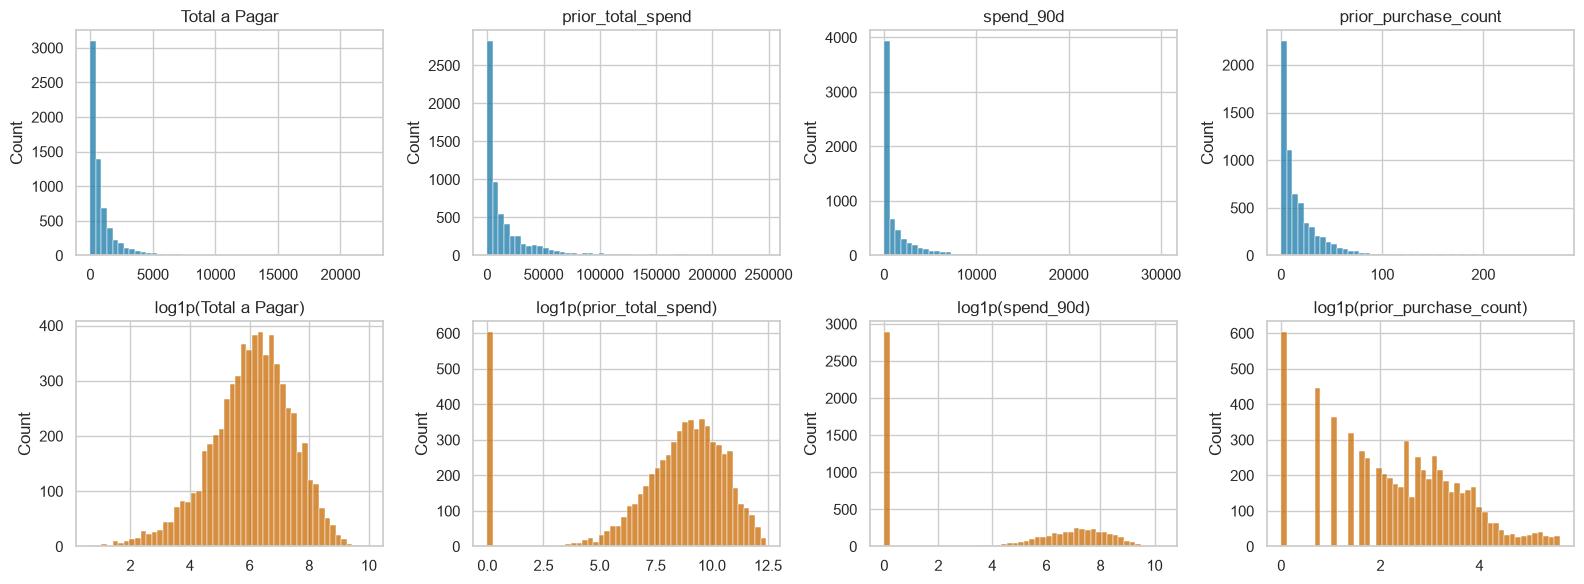

most skewed columns:
Total Desc_ Global              27.5
prior_max_purchase_value        21.3
spend_365d                      20.4
Total Portes                    19.5
prior_mean_purchase_value       18.8
prior_mean_gap_days              9.3
prior_std_gap_days               7.8
days_since_previous_purchase     6.5


In [14]:
money = ["Total a Pagar", "prior_total_spend", "spend_90d", "prior_purchase_count"]

fig, axes = plt.subplots(2, len(money), figsize=(4 * len(money), 6))
for i, col in enumerate(money):
    sns.histplot(filled[col], bins=50, ax=axes[0, i], color=PLOT_BLUE)
    sns.histplot(np.log1p(filled[col]), bins=50, ax=axes[1, i], color=PLOT_ORANGE)
    axes[0, i].set_title(col)
    axes[1, i].set_title(f"log1p({col})")
    axes[0, i].set_xlabel("")
    axes[1, i].set_xlabel("")
plt.tight_layout()
plt.show()

print("most skewed columns:")
print(filled[numeric].skew().sort_values(ascending=False).round(1).head(8).to_string())

<div class="alert alert-block alert-warning">

- Money and count columns are concentrated near zero with long right tails (skewness up to 27);
- After `log1p` the distributions become roughly symmetric.

</div>

14: Categorical columns against the target.

In [15]:
for col in categorical:
    table = (filled.groupby(col, dropna=False)[TARGET]
             .agg(rows="size", repeat_rate="mean")
             .sort_values("rows", ascending=False).round(3))
    print(f"\n{col} ({filled[col].nunique()} levels)")
    print(table.head(6).to_string())


payment_type (9 levels)
                           rows  repeat_rate
payment_type                                
Maybe Tomorrow Payment 7   4565        0.527
Maybe Tomorrow Payment 12   991        0.543
Maybe Tomorrow Payment 9    502        0.950
NaN                         195        0.564
Maybe Tomorrow Payment 10   134        0.403
Maybe Tomorrow Payment 8     40        0.325

salesperson (9 levels)
                  rows  repeat_rate
salesperson                        
VLOOKUP Master 1  4054        0.624
VLOOKUP Master 4  1461        0.394
VLOOKUP Master 9   384        0.547
VLOOKUP Master 7   201        0.483
NaN                194        0.598
VLOOKUP Master 2   123        0.602

commercial_zone (5 levels)
                             rows  repeat_rate
commercial_zone                               
Decorative Dashboard Zone 4  6260        0.565
Decorative Dashboard Zone 2   151        0.411
Decorative Dashboard Zone 3    56        0.357
Decorative Dashboard Zone 6     1       

<div class="alert alert-block alert-warning">

- `payment_type = Payment 9` repeats 95% of the time on 502 rows, against 53-54% for the two most common types: the strongest categorical signal;
- `salesperson` separates well: Master 1 (4,054 rows) 62% vs Master 4 (1,461 rows) 39%;
- `document_series` is flat (about 56% in every level);
- `commercial_zone` and `warehouse` are almost constant, with levels of 1 row (0% rate, not evidence);
- `transport_method` has 80 levels;
- Missing categories repeat at about the overall rate (56-64%).

</div>

15: Look at numeric columns by class.

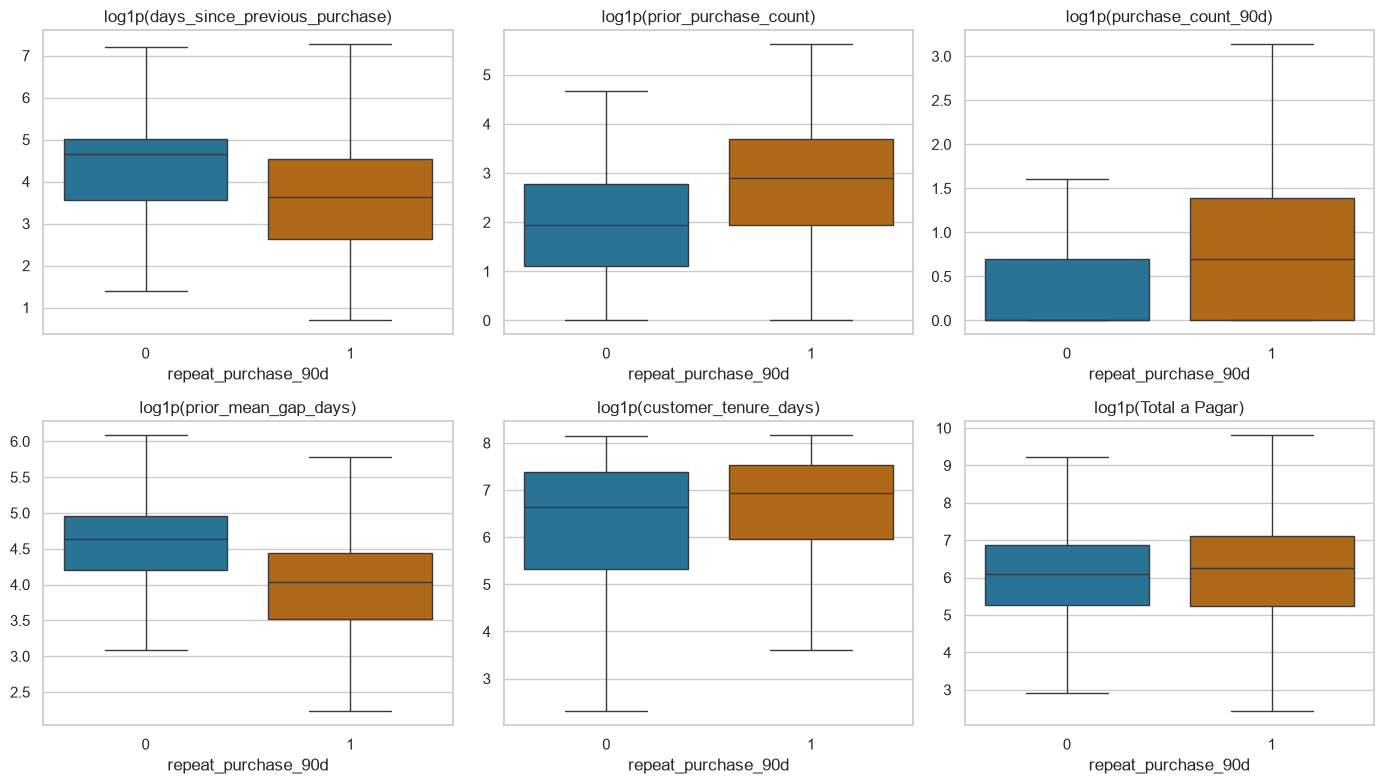

median by class:
repeat_purchase_90d               0       1
days_since_previous_purchase  105.0    37.0
prior_purchase_count            6.0    17.0
purchase_count_90d              0.0     1.0
prior_mean_gap_days           101.6    55.8
customer_tenure_days          769.0  1024.0
Total a Pagar                 443.4   520.0


In [16]:
key = ["days_since_previous_purchase", "prior_purchase_count", "purchase_count_90d",
       "prior_mean_gap_days", "customer_tenure_days", "Total a Pagar"]
clean = filled.loc[~anomalies.any(axis=1)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), key):
    sns.boxplot(x=clean[TARGET], y=np.log1p(clean[col]), ax=ax, showfliers=False,
                hue=clean[TARGET], palette=[PLOT_BLUE, PLOT_ORANGE], legend=False)
    ax.set_title(f"log1p({col})")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("median by class:")
print(clean.groupby(TARGET)[key].median().T.round(1).to_string())

<div class="alert alert-block alert-warning">

- Customers who repeat bought more recently (median 37 vs 105 days since the previous purchase), more often (17 vs 6 previous purchases) and at shorter intervals (56 vs 102 days);
- The value of the current order hardly differs between classes (520 vs 443);
- Repeat purchase is a matter of frequency and recency of the relationship, not of the size of this order.

</div>

16: Multivariate view.

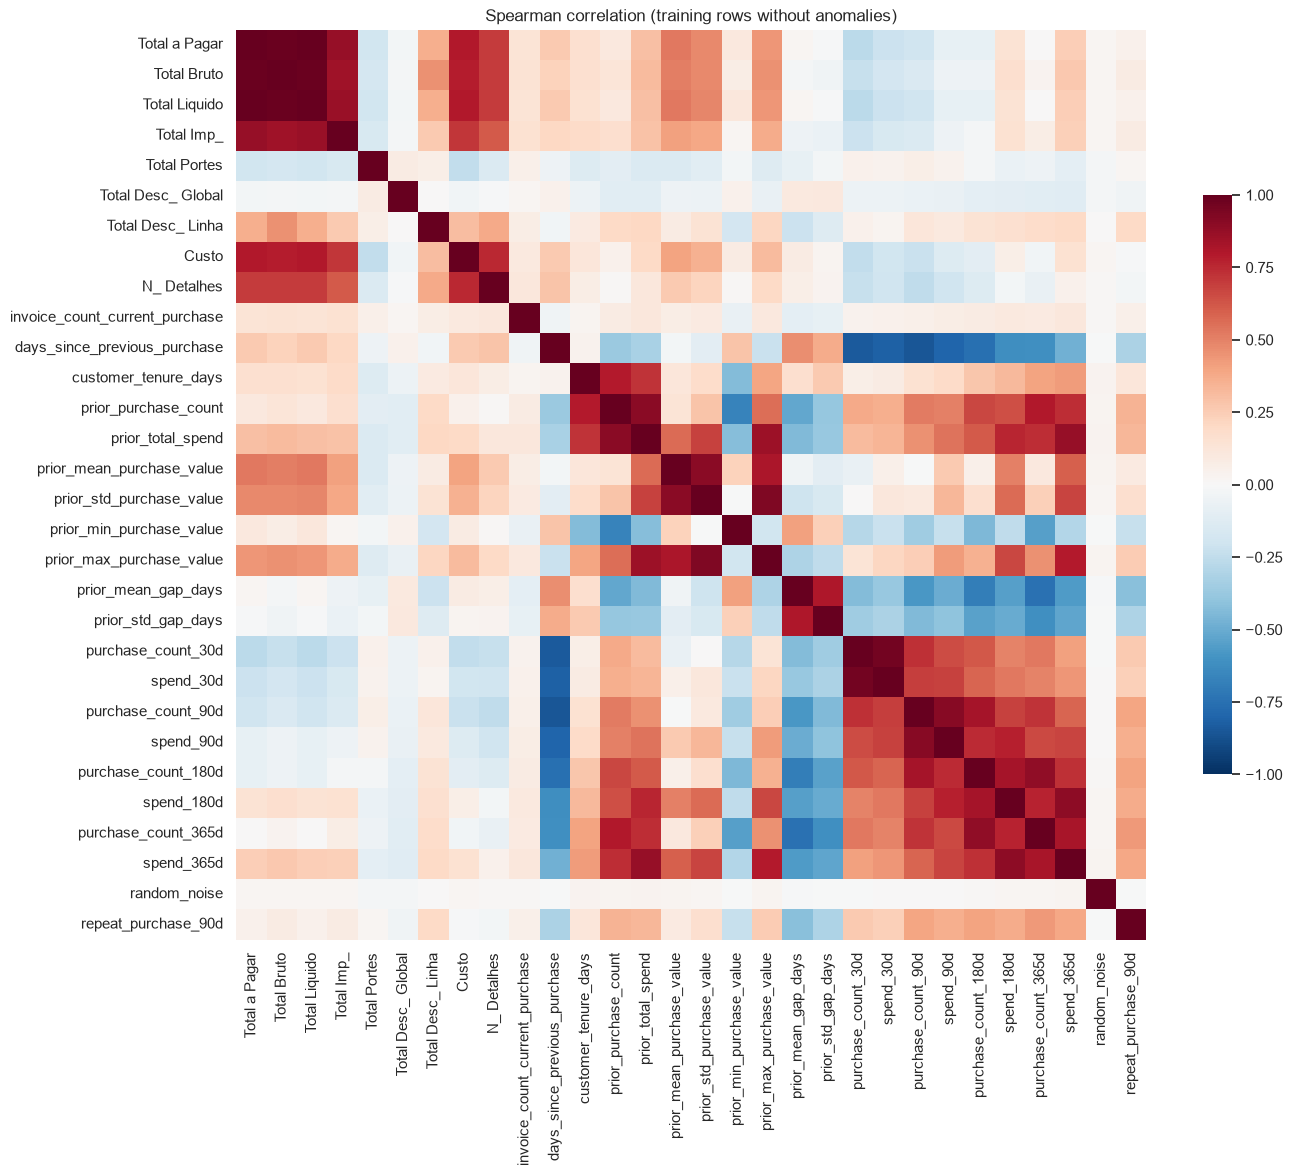

7 pairs with |rho| >= 0.9:
Total a Pagar             Total Liquido               1.000
Total Bruto               Total Liquido               0.991
Total a Pagar             Total Bruto                 0.991
purchase_count_30d        spend_30d                   0.966
prior_std_purchase_value  prior_max_purchase_value    0.937
purchase_count_90d        spend_90d                   0.910
prior_purchase_count      prior_total_spend           0.905

correlation with the target:
purchase_count_365d               0.434
prior_mean_gap_days              -0.419
purchase_count_180d               0.403
purchase_count_90d                0.391
spend_365d                        0.386
spend_180d                        0.371
spend_90d                         0.360
prior_purchase_count              0.345
prior_total_spend                 0.332
days_since_previous_purchase     -0.314
prior_std_gap_days               -0.311
purchase_count_30d                0.261
prior_max_purchase_value          0.256
spe

In [17]:
cols = [c for c in numeric if c != "customer_id"] + [TARGET]
corr = clean[cols].corr(method="spearman")

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.6})
plt.title("Spearman correlation (training rows without anomalies)")
plt.tight_layout()
plt.show()

features_corr = corr.drop(index=TARGET, columns=TARGET)
upper = features_corr.where(np.triu(np.ones(features_corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s.abs() >= 0.9].sort_values(ascending=False)
print(f"{len(pairs)} pairs with |rho| >= 0.9:")
print(pairs.round(3).to_string())

print("\ncorrelation with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

<div class="alert alert-block alert-warning">

- Redundant blocks. `Total a Pagar`, `Total Bruto` and `Total Liquido` (rho >= 0.99); count and spend in the same window (0.91-0.97); `prior_purchase_count` and `prior_total_spend` (0.90); `prior_std_purchase_value` and `prior_max_purchase_value` (0.94);
- What drives the target. History and recency: purchase counts in the windows (0.39-0.44), mean gap between purchases (-0.42), days since the previous purchase (-0.31).Current-order amounts barely relate (|rho| < 0.08);
- `random_noise` sits at -0.007, the reference for "no relation".

</div>

17: Look at stability over time.

In [18]:
# Is the outcome stable over time? Test lies after the last training date.
print(filled.groupby(filled["purchase_date"].dt.year)[TARGET]
      .agg(rows="size", repeat_rate="mean").round(3).T.to_string())

purchase_date     2015     2016     2017     2018     2019     2020     2021     2022     2023     2024    2025
rows           335.000  420.000  670.000  716.000  646.000  670.000  782.000  628.000  767.000  757.000  78.000
repeat_rate      0.534    0.514    0.633    0.538    0.522    0.594    0.549    0.481    0.581    0.602   0.628


<div class="alert alert-block alert-warning">

- The repeat rate moves between 48% and 63% with no trend, so the relation between features and target should hold in the test period;
- 2025 has only 78 rows, so its 63% is not a reliable estimate.

</div>

# <font color='#E8800A'>2. Clean and pre-process</font> <a class="anchor" id="clean"></a>

18: Import the validation tools and build the preprocessing pipeline from a recipe.

In [19]:
import sklearn
from sklearn.base import BaseEstimator, OneToOneFeatureMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, SelectFromModel, SelectorMixin, VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedGroupKFold,
                                     StratifiedKFold, TimeSeriesSplit, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   RobustScaler, StandardScaler, TargetEncoder)
from sklearn.tree import DecisionTreeClassifier

sklearn.set_config(transform_output="pandas")   # every step returns a table with column names
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Found unknown categories")
warnings.filterwarnings("ignore", message="Found n_features_to_select")


def outer_splitter(task="classification", random_state=RANDOM_STATE):
    """5 repetitions of a stratified 2-fold split (5x2): 10 validation folds, each half of the rows."""
    return RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=random_state)


class Winsorizer(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Clips each column to its 1st and 99th percentiles, learned on the training rows."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        self.feature_names_in_, self.n_features_in_ = np.asarray(X.columns, dtype=object), X.shape[1]
        self.low_, self.high_ = X.quantile(self.lower), X.quantile(self.upper)
        return self

    def transform(self, X):
        return X.clip(self.low_, self.high_, axis=1)


class CorrelationFilter(SelectorMixin, BaseEstimator):
    """Filter: keeps the k columns most correlated with the target (point-biserial), then, going from the most to
    the least relevant, drops a column whose correlation with one already kept exceeds `redundancy`."""
    def __init__(self, k=None, redundancy=None):
        self.k, self.redundancy = k, redundancy

    def fit(self, X, y):
        self.feature_names_in_, self.n_features_in_ = np.asarray(X.columns, dtype=object), X.shape[1]
        relevance = X.corrwith(pd.Series(np.asarray(y), index=X.index)).abs().fillna(0)
        keep = list(relevance.sort_values(ascending=False).index[:self.k])
        if self.redundancy is not None:
            between = X[keep].corr().abs().fillna(0)
            kept = []
            for column in keep:
                if all(between.loc[column, other] <= self.redundancy for other in kept):
                    kept.append(column)
            keep = kept
        self.support_ = X.columns.isin(keep)
        return self

    def _get_support_mask(self):
        return self.support_


class VoteSelector(SelectorMixin, BaseEstimator):
    """Fits every member on the same columns and keeps the columns chosen by at least `minimum` of them."""
    def __init__(self, members, minimum=2):
        self.members, self.minimum = members, minimum

    def fit(self, X, y):
        self.feature_names_in_, self.n_features_in_ = np.asarray(X.columns, dtype=object), X.shape[1]
        votes = sum(clone(member).fit(X, y).get_support().astype(int) for member in self.members.values())
        self.support_ = votes >= self.minimum
        return self

    def _get_support_mask(self):
        return self.support_


SCALERS = {"none": None, "standard": StandardScaler, "min-max": MinMaxScaler, "robust": RobustScaler}


def make_encoder(encoding, drop):
    if encoding == "one-hot":
        return OneHotEncoder(drop=drop, handle_unknown="ignore", sparse_output=False)
    if encoding == "ordinal":
        return OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    if encoding == "target":   # each level -> its repeat rate, cross-fitted inside the training rows
        return TargetEncoder(target_type="binary",
                             cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
    raise ValueError(encoding)


def build_preprocessor(recipe):
    """The recipe as one pipeline: fill -> log1p -> outliers (numeric), fill -> encode (categorical), scale, select."""
    def numeric(log):
        steps = [("fill", SimpleImputer(strategy=recipe["fill"]["numeric"]))]
        if log:
            steps.append(("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        if recipe["outliers"] == "winsorize 1/99":
            steps.append(("winsorize", Winsorizer()))
        return Pipeline(steps)

    categorical = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="missing")),
                            ("encode", make_encoder(recipe["encoding"], recipe["drop"]))])
    blocks = [("log", numeric(True), [c for c in recipe["numeric"] if c in recipe["log1p"]]),
              ("num", numeric(False), [c for c in recipe["numeric"] if c not in recipe["log1p"]]),
              ("cat", categorical, recipe["categorical"])]
    steps = [("columns", ColumnTransformer([b for b in blocks if b[2]], verbose_feature_names_out=False))]
    if SCALERS[recipe["scaler"]] is not None:
        steps.append(("scale", SCALERS[recipe["scaler"]]()))
    if recipe["strategy"] is not None:
        steps.append(("select", recipe["strategy"]))
    return Pipeline(steps)


def prepared(recipe, model):
    """Preprocessing and model in one pipeline, so every fold refits both on its training rows only."""
    return Pipeline([("prep", build_preprocessor(recipe)), ("estimator", model)])

19: Apply the fixed rules to train and test.

In [20]:
def apply_rules(frame):
    frame = frame.copy()

    for column in ["days_since_previous_purchase", "prior_mean_gap_days",
                   "prior_mean_purchase_value", "spend_365d"]:
        frame.loc[frame[column] < 0, column] = np.nan
    for column in ["prior_mean_purchase_value", "spend_365d"]:
        frame.loc[frame[column] >= 1e9, column] = np.nan

    mean_from_totals = (frame["prior_total_spend"]
                        / frame["prior_purchase_count"].replace(0, np.nan))
    frame.loc[frame["prior_mean_purchase_value"] > 2 * mean_from_totals,
              "prior_mean_purchase_value"] = np.nan
    frame.loc[frame["prior_max_purchase_value"] > frame["prior_total_spend"] + 0.01,
              "prior_max_purchase_value"] = np.nan

    frame["prior_mean_purchase_value"] = (frame["prior_mean_purchase_value"]
                                          .fillna(mean_from_totals))
    return frame

empty_rows = train.isna().sum(axis=1) >= train.shape[1] - 5
print(f"empty rows removed: {empty_rows.sum()} from train,"
      f" {(test.isna().sum(axis=1) >= test.shape[1] - 5).sum()} in test")

train_clean = apply_rules(train.loc[~empty_rows])
test_clean = apply_rules(test)

checked = ["days_since_previous_purchase", "prior_mean_gap_days",
           "prior_mean_purchase_value", "spend_365d", "prior_max_purchase_value"]
print(pd.DataFrame({
    "train gaps before": train.loc[~empty_rows, checked].isna().sum(),
    "train gaps after": train_clean[checked].isna().sum(),
    "test gaps before": test[checked].isna().sum(),
    "test gaps after": test_clean[checked].isna().sum(),
}).to_string())
impossible = ((train_clean[checked] < 0) | (train_clean[checked] >= 1e9)).sum().sum()
print("impossible values left in train:", int(impossible))

empty rows removed: 65 from train, 0 in test
                              train gaps before  train gaps after  test gaps before  test gaps after
days_since_previous_purchase                796               812                52               54
prior_mean_gap_days                        1243              1259                76               78
prior_mean_purchase_value                   797               603                52               22
spend_365d                                  195               225                30               34
prior_max_purchase_value                    603               648                22               28
impossible values left in train: 0


<div class="alert alert-block alert-warning">

- 65 empty rows removed from train; test has none;
- Gaps rise by exactly the number of values set to missing (16 in each day column, 30 in `spend_365d`, 45 in `prior_max_purchase_value`);
- No impossible value is left;
- `prior_mean_purchase_value` gaps fall from 797 to 603: the 603 left are the customers with no previous purchase (structural gaps);
- Test receives the same corrections (52 to 22 gaps).

</div>

20: Define the features, the target and a reference recipe.

In [21]:
excluded = ["customer_id", "random_noise"]
features_num = [c for c in numeric if c not in excluded]
features_cat = list(categorical)

X = train_clean[features_cat + features_num]
y = train_clean[TARGET].astype(int)
groups = train_clean["customer_id"]
dates = train_clean["purchase_date"]

baseline_recipe = {
    "numeric": features_num, "categorical": features_cat,
    "fill": {"numeric": "median", "categorical": "own level"},
    "log1p": [], "outliers": "keep",
    "encoding": "one-hot", "drop": "first", "scaler": "robust",
    "strategy": None,
}
baseline = prepared(baseline_recipe, LogisticRegression(max_iter=1000))
print(f"{X.shape[0]:,} rows, {len(features_cat)} categorical + {len(features_num)} numeric features")

6,469 rows, 6 categorical + 28 numeric features


21: Use the most recent rows (2024 onwards) as a test with a known answer.

In [22]:
cutoff = pd.Timestamp("2024-01-01")
is_recent = (dates >= cutoff).to_numpy()
X_past, y_past = X.loc[~is_recent], y.loc[~is_recent]
X_recent, y_recent = X.loc[is_recent], y.loc[is_recent]

print(f"past:   {len(y_past):,} rows, up to {dates[~is_recent].max().date()},"
      f" repeat rate {y_past.mean():.3f}")
print(f"recent: {len(y_recent):,} rows, from {dates[is_recent].min().date()},"
      f" repeat rate {y_recent.mean():.3f}")

past:   5,634 rows, up to 2023-12-31, repeat rate 0.553
recent: 835 rows, from 2024-01-01, repeat rate 0.605


22: Compare three validation designs: random, grouped by customer and time-ordered.

In [23]:
past_order = dates.loc[~is_recent].sort_values(kind="stable").index

designs = {
    "random (outer_splitter 5x2)": (
        outer_splitter("classification", random_state=RANDOM_STATE),
        X_past, y_past, None),
    "grouped by customer (5)": (
        StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        X_past, y_past, groups.loc[~is_recent]),
    "time-ordered (5)": (
        TimeSeriesSplit(n_splits=5),
        X_past.loc[past_order], y_past.loc[past_order], None),
}
scoring = ["f1", "roc_auc", "balanced_accuracy"]

fitted_past = clone(baseline).fit(X_past, y_past)
truth = {"f1": f1_score(y_recent, fitted_past.predict(X_recent)),
         "roc_auc": roc_auc_score(y_recent, fitted_past.predict_proba(X_recent)[:, 1]),
         "balanced_accuracy": balanced_accuracy_score(y_recent, fitted_past.predict(X_recent))}

design_runs, rows = {}, []
for name, (splitter, X_d, y_d, g) in designs.items():
    run = cross_validate(baseline, X_d, y_d, groups=g, cv=splitter, scoring=scoring)
    design_runs[name] = run
    row = {"design": name, "folds": len(run["test_f1"])}
    for metric in scoring:
        row[f"{metric} est."] = run[f"test_{metric}"].mean()
        row[f"{metric} est. - truth"] = row[f"{metric} est."] - truth[metric]
    row["F1 fold sd"] = run["test_f1"].std(ddof=1)
    rows.append(row)

design_table = pd.DataFrame(rows).set_index("design")
print(design_table.round(4).to_string())
print("\ntruth on the recent rows:", {k: round(v, 4) for k, v in truth.items()})

floor = DummyClassifier(strategy="most_frequent").fit(X_past, y_past)
print("floor on the recent rows: F1", round(f1_score(y_recent, floor.predict(X_recent)), 4))

                             folds  f1 est.  f1 est. - truth  roc_auc est.  roc_auc est. - truth  balanced_accuracy est.  balanced_accuracy est. - truth  F1 fold sd
design                                                                                                                                                              
random (outer_splitter 5x2)     10   0.7273          -0.0270        0.7783                0.0076                  0.7126                          0.0068      0.0103
grouped by customer (5)          5   0.7245          -0.0299        0.7752                0.0045                  0.7141                          0.0083      0.0226
time-ordered (5)                 5   0.7172          -0.0371        0.7802                0.0096                  0.6955                         -0.0103      0.0221

truth on the recent rows: {'f1': 0.7543, 'roc_auc': 0.7706, 'balanced_accuracy': 0.7057}
floor on the recent rows: F1 0.7537


23: Check if the three designs agree on one decision (`log1p`).

In [24]:
log_columns = [c for c in features_num if (X[c].dropna() >= 0).all()]
probe = prepared({**baseline_recipe, "log1p": log_columns}, LogisticRegression(max_iter=1000))

probe_rows = []
for name, (splitter, X_d, y_d, g) in designs.items():
    run = cross_validate(probe, X_d, y_d, groups=g, cv=splitter, scoring=["f1", "roc_auc"])
    for metric in ["f1", "roc_auc"]:
        delta = run[f"test_{metric}"] - design_runs[name][f"test_{metric}"]
        probe_rows.append({"design": name, "metric": metric,
                           "mean gain": delta.mean(),
                           "SEM": delta.std(ddof=1) / np.sqrt(len(delta)),
                           "folds better": f"{(delta > 0).sum()}/{len(delta)}"})
print(pd.DataFrame(probe_rows).round(4).to_string(index=False))

                     design  metric  mean gain    SEM folds better
random (outer_splitter 5x2)      f1     0.0086 0.0017        10/10
random (outer_splitter 5x2) roc_auc     0.0036 0.0006        10/10
    grouped by customer (5)      f1     0.0123 0.0040          5/5
    grouped by customer (5) roc_auc     0.0056 0.0028          4/5
           time-ordered (5)      f1     0.0128 0.0042          5/5
           time-ordered (5) roc_auc     0.0056 0.0027          4/5


<div class="alert alert-block alert-warning">

- ROC-AUC does not depend on the share of positives, so it compares the designs fairly;
- All three are slightly optimistic against the recent rows (0.771): +0.008 random, +0.010 time-ordered, +0.005 grouped;
- F1 falls below the truth in all three (-0.027 to -0.037) because the repeat rate rose from 55.3% to 60.5%, and F1 rises with the share of positives;
- On the recent rows the reference model (F1 0.754) ties with the floor (0.754), even with ROC-AUC 0.771: the 0.5 threshold is not the best for F1;
- The three designs agree that `log1p` helps; the random one has a standard error about 2.5 times smaller (0.0017 vs 0.0040-0.0042);
- We use `outer_splitter` (5x2) for every comparison and keep the time-ordered holdout (train up to 2023, evaluate on 2024-25) as the final check;
- The grouped design asks about never-seen customers, which are only 5.5% of the test rows.

</div>

23b: Check how much each design leaks through the 90-day target.

The target of a row is 1 when the same customer buys again in the next 90 days, so the label of a training row is decided by *later* purchases. If one of those later purchases sits in the validation fold, the training label already carries information about a validation row. The cell counts, for each design, the share of training rows whose label is decided by a purchase in their own validation fold.

In [25]:
# For every row: the later purchases of the same customer, within 90 days, that decide its label
rows = train_clean[["customer_id", "purchase_date"]].assign(pos=np.arange(len(train_clean)))
label_window = {}
for _, purchases in rows.sort_values("purchase_date", kind="stable").groupby("customer_id"):
    when, pos = purchases["purchase_date"].to_numpy(), purchases["pos"].to_numpy()
    for i in range(len(purchases)):
        inside = (when > when[i]) & (when <= when[i] + np.timedelta64(90, "D"))
        label_window[pos[i]] = pos[inside]


def leak_share(splits):
    """Mean share of training rows whose label is decided by a purchase in the validation fold."""
    shares = []
    for fit_at, score_at in splits:
        scored = np.zeros(len(train_clean), dtype=bool)
        scored[score_at] = True
        shares.append(np.mean([scored[label_window[i]].any() for i in fit_at]))
    return np.mean(shares)


order = np.argsort(train_clean["purchase_date"].to_numpy(), kind="stable")
sorted_dates = train_clean["purchase_date"].to_numpy()[order]


def time_folds(gap_days):
    """TimeSeriesSplit on date order, dropping training rows less than `gap_days` before the validation fold."""
    for fit_at, score_at in TimeSeriesSplit(n_splits=5).split(order):
        keep = sorted_dates[fit_at] < sorted_dates[score_at[0]] - np.timedelta64(gap_days, "D")
        yield order[fit_at[keep]], order[score_at]


past = (train_clean["purchase_date"] < pd.Timestamp("2024-01-01")).to_numpy()
leak = pd.Series({
    "random (outer_splitter 5x2)": leak_share(outer_splitter("classification", random_state=RANDOM_STATE).split(X, y)),
    "time-ordered (5), no gap": leak_share(time_folds(0)),
    "time-ordered (5), 90-day gap": leak_share(time_folds(90)),
    "holdout 2024-25, no gap": leak_share([(np.where(past)[0], np.where(~past)[0])]),
}, name="training labels decided by a validation row")
print((leak * 100).round(1).astype(str).add(" %").to_string())

random (outer_splitter 5x2)     38.0 %
time-ordered (5), no gap         2.5 %
time-ordered (5), 90-day gap     0.0 %
holdout 2024-25, no gap          1.5 %


<div class="alert alert-block alert-warning">

- In the random folds about **38%** of the training rows have a label decided by a purchase in their own validation fold: the model is partly trained on answers that come from the rows it is scored on;
- Time-ordered folds reduce this to about 2.5%, and a **90-day gap** (dropping the training rows in the 90 days before each validation fold) removes it completely;
- Step 23 shows the practical cost on ROC-AUC is small here: against the recent rows, the random design was +0.008 optimistic and the time-ordered one +0.010. So the random folds are kept for **comparing options**, where every option has the same leak and their lower standard error separates options better, but their absolute scores are read as optimistic;
- The honest estimate is the time-ordered holdout (step 40). Even there, 87 training rows from late 2023 (about 1.5%) have labels decided by 2024 purchases; a 90-day gap before the cutoff would remove them.

</div>

24: Fix the folds and the comparison functions.

In [26]:
folds = list(outer_splitter("classification", random_state=RANDOM_STATE).split(X, y))
SCORING = ["f1", "roc_auc", "balanced_accuracy"]

def evaluate(recipe, model=None, frame=None):
    frame = X if frame is None else frame
    model = LogisticRegression(max_iter=1000) if model is None else model
    run = cross_validate(prepared(recipe, model),
                         frame, y, cv=folds, scoring=SCORING, return_estimator=True)
    return pd.DataFrame({
        "F1": run["test_f1"],
        "ROC-AUC": run["test_roc_auc"],
        "bal. acc.": run["test_balanced_accuracy"],
        "columns": [len(fitted.named_steps["prep"].get_feature_names_out())
                    for fitted in run["estimator"]],
    })

def paired_delta(scores, reference):
    delta = np.asarray(scores) - np.asarray(reference)
    sem = delta.std(ddof=1) / np.sqrt(len(delta))
    verdict = ("identical on every fold" if not delta.any()
               else "inside the noise" if abs(delta.mean()) <= 2 * sem
               else "better" if delta.mean() > 0 else "worse")
    return {"dF1": delta.mean(), "SEM": sem,
            "wins": f"{int((delta > 0).sum())}/{len(delta)}", "verdict": verdict}

reference = evaluate(baseline_recipe)
print(reference[["F1", "ROC-AUC", "bal. acc."]].agg(["mean", "std"]).round(4).to_string())
print(f"columns after encoding: {reference['columns'].iloc[0]}")

          F1  ROC-AUC  bal. acc.
mean  0.7323   0.7772     0.7116
std   0.0063   0.0077     0.0051
columns after encoding: 119


25: Compare treatments for the numeric columns: `log1p`, winsorize, or both.

In [27]:
nonneg = [c for c in features_num if (X[c].dropna() >= 0).all()]
print(f"log1p candidates: {len(nonneg)} of {len(features_num)} numeric columns")

treatments = {
    "none": {"log1p": [], "outliers": "keep"},
    "log1p": {"log1p": nonneg, "outliers": "keep"},
    "winsorize 1/99": {"log1p": [], "outliers": "winsorize 1/99"},
    "winsorize + log1p": {"log1p": nonneg, "outliers": "winsorize 1/99"},
}
treatment_runs = {name: (reference if name == "none"
                         else evaluate({**baseline_recipe, **change}))
                  for name, change in treatments.items()}

rows = {}
for name, run in treatment_runs.items():
    row = {"F1": run["F1"].mean(), "ROC-AUC": run["ROC-AUC"].mean()}
    if name != "none":
        row.update(paired_delta(run["F1"], reference["F1"]))
        row["dAUC"] = (run["ROC-AUC"] - reference["ROC-AUC"]).mean()
    rows[name] = row
print(pd.DataFrame(rows).T.to_string(float_format="{:.4f}".format, na_rep=""))

both_vs_log = paired_delta(treatment_runs["winsorize + log1p"]["F1"],
                           treatment_runs["log1p"]["F1"])
print("\nwinsorize + log1p vs log1p alone:",
      {k: (round(v, 4) if isinstance(v, float) else v) for k, v in both_vs_log.items()})

log1p candidates: 28 of 28 numeric columns


                      F1 ROC-AUC    dF1    SEM   wins verdict   dAUC
none              0.7323  0.7772                                    
log1p             0.7421  0.7825 0.0098 0.0016   9/10  better 0.0053
winsorize 1/99    0.7345  0.7781 0.0023 0.0007   8/10  better 0.0009
winsorize + log1p 0.7416  0.7825 0.0094 0.0016  10/10  better 0.0053

winsorize + log1p vs log1p alone: {'dF1': np.float64(-0.0004), 'SEM': np.float64(0.0003), 'wins': '4/10', 'verdict': 'inside the noise'}


<div class="alert alert-block alert-warning">

- `log1p` improves F1 by +0.0098 ± 0.0016 (9 of 10 folds) and ROC-AUC by +0.005;
- Winsorize alone helps less (+0.002);
- Winsorize added to `log1p` stays inside the noise (-0.0004 ± 0.0003, 4 of 10 folds);
- We keep `log1p` on every numeric column, without winsorize.

</div>

26: Benchmark three encoders against four scalers.

In [28]:
chosen_treatment = treatments["log1p"]
encoders = ["one-hot", "ordinal", "target"]
scalers = ["none", "standard", "min-max", "robust"]

encoding_runs = {
    (encoding, scaler): evaluate({**baseline_recipe, **chosen_treatment,
                                  "encoding": encoding, "scaler": scaler})
    for encoding in encoders for scaler in scalers
}

encoding_board = pd.DataFrame.from_dict(
    {pair: {"F1": run["F1"].mean(), "F1 SEM": run["F1"].sem(),
            "ROC-AUC": run["ROC-AUC"].mean(), "columns": run["columns"].mean()}
     for pair, run in encoding_runs.items()},
    orient="index",
).rename_axis(["encoding", "scaler"])

best_pair = encoding_board["F1"].idxmax()
comparison = pd.DataFrame.from_dict(
    {pair: paired_delta(run["F1"], encoding_runs[best_pair]["F1"]) for pair, run in encoding_runs.items()},
    orient="index",
).rename_axis(["encoding", "scaler"])
print(encoding_board.join(comparison[["dF1", "wins", "verdict"]])
      .to_string(float_format="{:.4f}".format))

# a tie goes to the simpler option: fewest columns among the pairs not worse than the best one
tied = comparison.index[comparison["verdict"] != "worse"]
selected_encoding, selected_scaler = (encoding_board.loc[tied]
                                      .sort_values(["columns", "F1"], ascending=[True, False]).index[0])
winner = encoding_runs[selected_encoding, selected_scaler]
print(f"\nhighest mean F1: {best_pair[0]} + {best_pair[1]}")
print(f"selected: {selected_encoding} + {selected_scaler} (fewest columns among the pairs not worse than it)")

                      F1  F1 SEM  ROC-AUC  columns     dF1  wins                  verdict
encoding scaler                                                                          
one-hot  none     0.7420  0.0028   0.7824 118.5000 -0.0014  3/10                    worse
         standard 0.7404  0.0030   0.7781 118.5000 -0.0030  1/10                    worse
         min-max  0.7434  0.0026   0.7834 118.5000  0.0000  0/10  identical on every fold
         robust   0.7421  0.0029   0.7825 118.5000 -0.0014  3/10         inside the noise
ordinal  none     0.7375  0.0028   0.7794  34.0000 -0.0060  1/10                    worse
         standard 0.7372  0.0027   0.7793  34.0000 -0.0062  1/10                    worse
         min-max  0.7386  0.0031   0.7803  34.0000 -0.0049  2/10                    worse
         robust   0.7379  0.0027   0.7794  34.0000 -0.0055  1/10                    worse
target   none     0.7413  0.0036   0.7842  34.0000 -0.0021  3/10         inside the noise
         s

<div class="alert alert-block alert-warning">

- One-hot with min-max has the highest mean F1 (0.7434), but needs about 119 columns;
- Target encoding with min-max is inside the noise of it (-0.0009, ahead on 2 of 10 folds) with 34 columns, and has the highest ROC-AUC (0.786). A tie goes to the simpler option, so target encoding with min-max is selected;
- Ordinal encoding loses on 8 or 9 of 10 folds (-0.005 to -0.006);
- Target encoding replaces each level by its repeat rate in the training rows, the signal seen in step 14; it is fitted inside each fold (and cross-fitted within the training rows), so it does not leak;
- Min-max is the best scaler for every encoder, but the differences are small (up to 0.003).

</div>

27: Fix the chosen recipe.

In [29]:
recipe = {**baseline_recipe, **chosen_treatment,
          "encoding": selected_encoding, "scaler": selected_scaler}
reference = winner
print({k: v for k, v in recipe.items() if k not in ("numeric", "categorical", "log1p")})
print(f"reference F1 {reference['F1'].mean():.4f}, ROC-AUC {reference['ROC-AUC'].mean():.4f},"
      f" bal. acc. {reference['bal. acc.'].mean():.4f}")

{'fill': {'numeric': 'median', 'categorical': 'own level'}, 'outliers': 'keep', 'encoding': 'target', 'drop': 'first', 'scaler': 'min-max', 'strategy': None}
reference F1 0.7425, ROC-AUC 0.7858, bal. acc. 0.7160


28: Build the candidate features: history flags, frequency and recency ratios, and `clientes.csv` columns.

In [30]:
CLIENT_COLUMNS = ["country_or_region", "commercial_region", "customer_since_year"]

def add_features(frame):
    frame = frame.copy()
    count = frame["prior_purchase_count"]

    frame["has_history"] = (count >= 1).astype(int)
    frame["has_two_purchases"] = (count >= 2).astype(int)
    frame["has_three_purchases"] = (count >= 3).astype(int)

    frame["recency_ratio"] = (frame["days_since_previous_purchase"]
                              / frame["prior_mean_gap_days"].replace(0, np.nan))
    frame["purchases_per_year"] = count / (frame["customer_tenure_days"] / 365.25 + 1 / 12)
    frame["recent_share_90d"] = (frame["purchase_count_90d"]
                                 / frame["purchase_count_365d"].replace(0, np.nan))

    frame["margin_share"] = (frame["Total Liquido"] - frame["Custo"]) / frame["Total Liquido"]
    frame["discount_share"] = (frame["Total Desc_ Linha"]
                               / (frame["Total Bruto"] + frame["Total Desc_ Linha"]))

    return frame.join(clientes.set_index("customer_id")[CLIENT_COLUMNS], on="customer_id")

train_fe = add_features(train_clean)
test_fe = add_features(test_clean)
assert train_fe.index.equals(train_clean.index) and test_fe.index.equals(test_clean.index)

new_features = ["has_history", "has_two_purchases", "has_three_purchases", "recency_ratio",
                "purchases_per_year", "recent_share_90d", "margin_share", "discount_share"]
summary = train_fe[new_features].describe().T[["count", "mean", "min", "50%", "max"]]
summary["Spearman with target"] = train_fe[new_features].corrwith(train_fe[TARGET], method="spearman")
print(summary.round(3).to_string())

                      count   mean    min    50%      max  Spearman with target
has_history          6469.0  0.907  0.000  1.000    1.000                 0.146
has_two_purchases    6469.0  0.838  0.000  1.000    1.000                 0.186
has_three_purchases  6469.0  0.782  0.000  1.000    1.000                 0.209
recency_ratio        5031.0  1.500  0.001  0.831  478.667                -0.056
purchases_per_year   6469.0  7.318  0.000  4.339   59.090                 0.433
recent_share_90d     5626.0  0.251  0.000  0.200    1.000                 0.177
margin_share         6469.0  0.548 -4.292  0.498    1.000                 0.118
discount_share       6469.0  0.087  0.000  0.044    0.494                 0.222


29: Test each group of candidates against the reference.

In [31]:
candidates = {
    "history flags": {"numeric": ["has_history", "has_two_purchases", "has_three_purchases"],
                      "categorical": [], "log1p": []},
    "recency_ratio": {"numeric": ["recency_ratio"], "categorical": [], "log1p": ["recency_ratio"]},
    "purchases_per_year": {"numeric": ["purchases_per_year"], "categorical": [],
                           "log1p": ["purchases_per_year"]},
    "recent_share_90d": {"numeric": ["recent_share_90d"], "categorical": [], "log1p": []},
    "margin & discount share": {"numeric": ["margin_share", "discount_share"],
                                "categorical": [], "log1p": []},
    "clientes: country + region": {"numeric": [],
                                   "categorical": ["country_or_region", "commercial_region"],
                                   "log1p": []},
    "clientes: customer_since_year": {"numeric": ["customer_since_year"], "categorical": [],
                                      "log1p": []},
}

def extended(extra):
    new_recipe = {**recipe,
                  "numeric": recipe["numeric"] + extra["numeric"],
                  "categorical": recipe["categorical"] + extra["categorical"],
                  "log1p": recipe["log1p"] + extra["log1p"]}
    return new_recipe, train_fe[new_recipe["categorical"] + new_recipe["numeric"]]

candidate_rows = {}
for name, extra in candidates.items():
    new_recipe, frame = extended(extra)
    run = evaluate(new_recipe, frame=frame)
    candidate_rows[name] = {**paired_delta(run["F1"], reference["F1"]),
                            "dAUC": (run["ROC-AUC"] - reference["ROC-AUC"]).mean()}
print(pd.DataFrame(candidate_rows).T.to_string(
    formatters={"dF1": "{:+.4f}".format, "SEM": "{:.4f}".format, "dAUC": "{:+.4f}".format}))

                                   dF1     SEM  wins           verdict     dAUC
history flags                  +0.0000  0.0004  7/10  inside the noise  -0.0001
recency_ratio                  +0.0006  0.0003  7/10            better  +0.0000
purchases_per_year             +0.0009  0.0004  8/10            better  +0.0001
recent_share_90d               +0.0002  0.0003  4/10  inside the noise  -0.0001
margin & discount share        +0.0006  0.0008  6/10  inside the noise  +0.0007
clientes: country + region     +0.0007  0.0006  6/10  inside the noise  +0.0008
clientes: customer_since_year  +0.0009  0.0007  6/10  inside the noise  +0.0005


30: Test all candidates together.

In [32]:
all_extra = {key: sum((extra[key] for extra in candidates.values()), [])
             for key in ["numeric", "categorical", "log1p"]}
recipe_full, X_full = extended(all_extra)

with_all = evaluate(recipe_full, frame=X_full)
result = paired_delta(with_all["F1"], reference["F1"])
print(f"F1 {reference['F1'].mean():.4f} -> {with_all['F1'].mean():.4f}"
      f"  dF1 {result['dF1']:+.4f} +- {result['SEM']:.4f}, better on {result['wins']}"
      f" -> {result['verdict'].upper()}"
      f"  | dAUC {(with_all['ROC-AUC'] - reference['ROC-AUC']).mean():+.4f}")
print(f"\ncolumns: {X.shape[1]} source columns before, {X_full.shape[1]} with the candidates")

F1 0.7425 -> 0.7440  dF1 +0.0015 +- 0.0011, better on 5/10 -> INSIDE THE NOISE  | dAUC +0.0016

columns: 34 source columns before, 45 with the candidates


<div class="alert alert-block alert-warning">

- Each group alone changes F1 by between +0.0000 and +0.0009; `recency_ratio` (+0.0006 ± 0.0003) and `purchases_per_year` (+0.0009 ± 0.0004) pass the two-standard-error rule, the others stay inside the noise;
- `purchases_per_year` has Spearman 0.43 with the target, but its gain is small: the linear model already combines `prior_purchase_count` and `customer_tenure_days`;
- All together: F1 0.7425 to 0.7440 (+0.0015 ± 0.0011, better on 5 of 10 folds, inside the noise), ROC-AUC +0.0016;
- No candidate harms the model, and a selector cannot keep a feature that does not exist yet;
- All 11 candidates go on to feature selection (45 source columns instead of 34).

</div>

# <font color='#E8800A'>3. Feature selection</font> <a class="anchor" id="selection"></a>

31: Set up the selection runs and the reference with all features.

In [33]:
from collections import Counter

def selection_run(strategy, model=None):
    model = LogisticRegression(max_iter=1000) if model is None else model
    run = cross_validate(
        prepared({**recipe_full, "strategy": strategy}, model),
        X_full, y, cv=folds, scoring=SCORING, return_estimator=True)
    kept = [list(fitted.named_steps["prep"].get_feature_names_out()) for fitted in run["estimator"]]
    return pd.DataFrame({"F1": run["test_f1"], "ROC-AUC": run["test_roc_auc"],
                         "bal. acc.": run["test_balanced_accuracy"],
                         "n": [len(columns) for columns in kept], "kept": kept})

def one_stage(selector):
    return selector

board, results = {}, {}

def report(name, run, verdict=None):
    board[name] = run
    row = {"columns": run["n"].mean(), "F1": run["F1"].mean(), "ROC-AUC": run["ROC-AUC"].mean()}
    if verdict is not None:
        row["verdict"] = verdict
    elif name != "all features":
        row.update(paired_delta(run["F1"], board["all features"]["F1"]))
    results[name] = row
    kept = Counter(column for columns in run["kept"] for column in columns)
    usual = [column for column, n in kept.most_common() if n > len(folds) / 2]
    print(name, {k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})
    print(f"    kept in most folds ({len(usual)}): {', '.join(usual)}\n")

report("all features", selection_run(None))

all features {'columns': np.float64(45.0), 'F1': np.float64(0.744), 'ROC-AUC': np.float64(0.7873)}
    kept in most folds (45): Total a Pagar, Total Bruto, Total Liquido, Total Imp_, Total Portes, Total Desc_ Global, Total Desc_ Linha, Custo, N_ Detalhes, invoice_count_current_purchase, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_value, prior_min_purchase_value, prior_max_purchase_value, prior_mean_gap_days, prior_std_gap_days, purchase_count_30d, spend_30d, purchase_count_90d, spend_90d, purchase_count_180d, spend_180d, purchase_count_365d, spend_365d, recency_ratio, purchases_per_year, has_history, has_two_purchases, has_three_purchases, recent_share_90d, margin_share, discount_share, customer_since_year, payment_type, salesperson, commercial_zone, transport_method, warehouse, document_series, country_or_region, commercial_region



32: Try filter methods: variance, relevance and redundancy.

In [34]:
report("VarianceThreshold(0)", selection_run(one_stage(VarianceThreshold(threshold=0.0))))
for k in (10, 20, 30):
    report(f"relevance k={k}",
           selection_run(one_stage(CorrelationFilter(k=k, redundancy=None))))
report("redundancy 0.8", selection_run(one_stage(CorrelationFilter(k=None, redundancy=0.8))))

VarianceThreshold(0) {'columns': np.float64(45.0), 'F1': np.float64(0.744), 'ROC-AUC': np.float64(0.7873), 'dF1': np.float64(0.0), 'SEM': np.float64(0.0), 'wins': '0/10', 'verdict': 'identical on every fold'}
    kept in most folds (45): Total a Pagar, Total Bruto, Total Liquido, Total Imp_, Total Portes, Total Desc_ Global, Total Desc_ Linha, Custo, N_ Detalhes, invoice_count_current_purchase, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_value, prior_min_purchase_value, prior_max_purchase_value, prior_mean_gap_days, prior_std_gap_days, purchase_count_30d, spend_30d, purchase_count_90d, spend_90d, purchase_count_180d, spend_180d, purchase_count_365d, spend_365d, recency_ratio, purchases_per_year, has_history, has_two_purchases, has_three_purchases, recent_share_90d, margin_share, discount_share, customer_since_year, payment_type, salesperson, commercial_zone, transport_method, warehouse, docum

relevance k=10 {'columns': np.float64(10.0), 'F1': np.float64(0.7259), 'ROC-AUC': np.float64(0.7627), 'dF1': np.float64(-0.0181), 'SEM': np.float64(0.0014), 'wins': '0/10', 'verdict': 'worse'}
    kept in most folds (9): prior_purchase_count, prior_mean_gap_days, purchase_count_90d, spend_90d, purchase_count_180d, spend_180d, purchase_count_365d, purchases_per_year, spend_365d



relevance k=20 {'columns': np.float64(20.0), 'F1': np.float64(0.7399), 'ROC-AUC': np.float64(0.7789), 'dF1': np.float64(-0.0041), 'SEM': np.float64(0.0012), 'wins': '1/10', 'verdict': 'worse'}
    kept in most folds (20): days_since_previous_purchase, prior_purchase_count, prior_total_spend, prior_min_purchase_value, prior_max_purchase_value, prior_mean_gap_days, prior_std_gap_days, purchase_count_30d, spend_30d, purchase_count_90d, spend_90d, purchase_count_180d, spend_180d, purchase_count_365d, spend_365d, purchases_per_year, commercial_region, transport_method, discount_share, payment_type



relevance k=30 {'columns': np.float64(30.0), 'F1': np.float64(0.7445), 'ROC-AUC': np.float64(0.7863), 'dF1': np.float64(0.0005), 'SEM': np.float64(0.001), 'wins': '5/10', 'verdict': 'inside the noise'}
    kept in most folds (30): Total Desc_ Linha, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_total_spend, prior_std_purchase_value, prior_min_purchase_value, prior_max_purchase_value, prior_mean_gap_days, prior_std_gap_days, purchase_count_30d, spend_30d, purchase_count_90d, spend_90d, purchase_count_180d, spend_180d, purchase_count_365d, spend_365d, purchases_per_year, has_history, has_two_purchases, has_three_purchases, discount_share, payment_type, salesperson, transport_method, commercial_region, recent_share_90d, customer_since_year, margin_share



redundancy 0.8 {'columns': np.float64(31.3), 'F1': np.float64(0.7442), 'ROC-AUC': np.float64(0.788), 'dF1': np.float64(0.0002), 'SEM': np.float64(0.0009), 'wins': '5/10', 'verdict': 'inside the noise'}
    kept in most folds (31): Total Bruto, Total Imp_, Total Portes, Total Desc_ Global, Custo, N_ Detalhes, invoice_count_current_purchase, days_since_previous_purchase, prior_min_purchase_value, prior_max_purchase_value, prior_mean_gap_days, purchase_count_90d, purchase_count_365d, recency_ratio, has_three_purchases, recent_share_90d, margin_share, discount_share, customer_since_year, payment_type, salesperson, transport_method, warehouse, document_series, commercial_region, prior_std_gap_days, spend_180d, Total Desc_ Linha, spend_30d, commercial_zone, prior_total_spend



<div class="alert alert-block alert-warning">

- `VarianceThreshold(0)` removes nothing;
- Relevance (point-biserial correlation with the target) with a fixed budget loses at small budgets: k=10 costs -0.018 on every fold and k=20 -0.004; k=30 is inside the noise (+0.0005);
- The top 10 by relevance are almost all window counts and spends, which repeat the same information;
- The redundancy rule (0.8) alone stays inside the noise with about 31 columns instead of 45 (+0.0002 ± 0.0009).

</div>

33: Try RFE as a wrapper, choosing the width on validation.

 k     F1  F1 SEM  ROC-AUC
 5 0.7329  0.0021   0.7688
10 0.7435  0.0024   0.7824
15 0.7439  0.0027   0.7841
20 0.7427  0.0032   0.7855
25 0.7438  0.0034   0.7862
30 0.7441  0.0032   0.7869
35 0.7442  0.0035   0.7872
40 0.7442  0.0034   0.7873
45 0.7440  0.0034   0.7873

selected k = 40 by mean validation F1


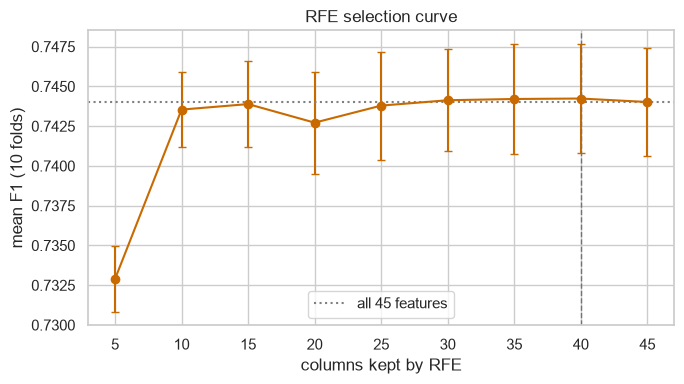

RFE (k=40, validation-selected) {'columns': np.float64(40.0), 'F1': np.float64(0.7442), 'ROC-AUC': np.float64(0.7873), 'verdict': 'no unbiased delta'}
    kept in most folds (44): Total Imp_, Total Desc_ Linha, invoice_count_current_purchase, prior_mean_purchase_value, prior_max_purchase_value, spend_30d, purchase_count_90d, spend_180d, purchase_count_365d, recency_ratio, purchases_per_year, has_history, margin_share, salesperson, commercial_zone, transport_method, warehouse, country_or_region, commercial_region, Total Portes, Total Desc_ Global, Custo, customer_tenure_days, prior_purchase_count, prior_mean_gap_days, purchase_count_30d, purchase_count_180d, spend_365d, discount_share, spend_90d, customer_since_year, Total Bruto, prior_total_spend, prior_std_purchase_value, prior_std_gap_days, has_two_purchases, recent_share_90d, payment_type, Total a Pagar, N_ Detalhes, has_three_purchases, days_since_previous_purchase, document_series, Total Liquido



In [35]:
widths = list(range(5, 46, 5))
rfe_runs = {k: selection_run(one_stage(
                RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=k)))
            for k in widths}

rfe_curve = pd.DataFrame({"k": widths,
                          "F1": [rfe_runs[k]["F1"].mean() for k in widths],
                          "F1 SEM": [rfe_runs[k]["F1"].sem() for k in widths],
                          "ROC-AUC": [rfe_runs[k]["ROC-AUC"].mean() for k in widths]})
chosen_k = int(rfe_curve.loc[rfe_curve["F1"] == rfe_curve["F1"].max(), "k"].min())
print(rfe_curve.round(4).to_string(index=False))
print(f"\nselected k = {chosen_k} by mean validation F1")

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(rfe_curve["k"], rfe_curve["F1"], yerr=rfe_curve["F1 SEM"],
            marker="o", capsize=3, color=PLOT_ORANGE)
ax.axhline(results["all features"]["F1"], color="grey", linestyle=":", label="all 45 features")
ax.axvline(chosen_k, color="0.45", linestyle="--", linewidth=1)
ax.set(xlabel="columns kept by RFE", ylabel="mean F1 (10 folds)", title="RFE selection curve")
ax.legend()
plt.tight_layout()
plt.show()

report(f"RFE (k={chosen_k}, validation-selected)", rfe_runs[chosen_k],
       verdict="no unbiased delta")

34: Try embedded methods: L1 and tree importance.

In [36]:
L1 = SelectFromModel(estimator=LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1, max_iter=1000),
                     threshold=1e-08)
TREE = SelectFromModel(estimator=DecisionTreeClassifier(random_state=42), threshold="median")

report("L1 embedded", selection_run(one_stage(L1)))
report("tree importance embedded", selection_run(one_stage(TREE)))

L1 embedded {'columns': np.float64(11.9), 'F1': np.float64(0.7398), 'ROC-AUC': np.float64(0.7805), 'dF1': np.float64(-0.0042), 'SEM': np.float64(0.0014), 'wins': '3/10', 'verdict': 'worse'}
    kept in most folds (11): Total Desc_ Linha, prior_mean_gap_days, purchase_count_90d, spend_90d, purchase_count_365d, customer_since_year, has_history, transport_method, Total Imp_, Custo, salesperson



tree importance embedded {'columns': np.float64(23.0), 'F1': np.float64(0.7423), 'ROC-AUC': np.float64(0.7835), 'dF1': np.float64(-0.0017), 'SEM': np.float64(0.001), 'wins': '4/10', 'verdict': 'inside the noise'}
    kept in most folds (22): N_ Detalhes, prior_total_spend, prior_std_gap_days, spend_180d, purchase_count_365d, spend_365d, purchases_per_year, margin_share, transport_method, commercial_region, prior_mean_purchase_value, prior_std_purchase_value, recency_ratio, Custo, prior_min_purchase_value, prior_mean_gap_days, discount_share, document_series, Total Imp_, Total Desc_ Linha, salesperson, customer_tenure_days



35: Combine the three families as a sequence and as a vote.

In [37]:
FILTER = CorrelationFilter(k=None, redundancy=0.8)
WRAPPER = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=chosen_k)

sequence_strategy = Pipeline([("filter", FILTER), ("wrapper", WRAPPER), ("embedded", L1)])
vote_strategy = VoteSelector({"filter": FILTER, "wrapper": WRAPPER, "embedded": L1}, minimum=2)

report("sequence: filter -> wrapper -> embedded", selection_run(sequence_strategy))
report("vote: 2 of 3 families", selection_run(vote_strategy))

sequence: filter -> wrapper -> embedded {'columns': np.float64(9.9), 'F1': np.float64(0.7411), 'ROC-AUC': np.float64(0.7805), 'dF1': np.float64(-0.0029), 'SEM': np.float64(0.0014), 'wins': '2/10', 'verdict': 'worse'}
    kept in most folds (8): prior_mean_gap_days, purchase_count_90d, purchase_count_365d, customer_since_year, Total Imp_, Total Desc_ Linha, Custo, prior_max_purchase_value



vote: 2 of 3 families {'columns': np.float64(30.8), 'F1': np.float64(0.7445), 'ROC-AUC': np.float64(0.7875), 'dF1': np.float64(0.0005), 'SEM': np.float64(0.0006), 'wins': '8/10', 'verdict': 'inside the noise'}
    kept in most folds (31): Total Imp_, Total Desc_ Linha, Custo, invoice_count_current_purchase, prior_max_purchase_value, prior_mean_gap_days, purchase_count_90d, purchase_count_365d, recency_ratio, margin_share, customer_since_year, salesperson, transport_method, warehouse, commercial_region, Total Portes, Total Desc_ Global, spend_180d, has_history, discount_share, spend_90d, Total Bruto, prior_std_gap_days, spend_30d, recent_share_90d, payment_type, commercial_zone, N_ Detalhes, has_three_purchases, days_since_previous_purchase, document_series



36: Compare all techniques and export the rule.

In [38]:
print(pd.DataFrame(results).T.to_string(
    formatters={"columns": "{:.1f}".format, "F1": "{:.4f}".format, "ROC-AUC": "{:.4f}".format,
                "dF1": lambda v: "" if pd.isna(v) else f"{v:+.4f}",
                "SEM": lambda v: "" if pd.isna(v) else f"{v:.4f}"}, na_rep=""))

combinations = {"sequence: filter -> wrapper -> embedded": sequence_strategy,
                "vote: 2 of 3 families": vote_strategy}
best_combination = max(combinations, key=lambda name: results[name]["dF1"])
recipe_final = {**recipe_full, "strategy": combinations[best_combination]}
print(f"\nexported strategy: {best_combination}")

                                        columns      F1 ROC-AUC      dF1     SEM  wins                  verdict
all features                               45.0  0.7440  0.7873                                                
VarianceThreshold(0)                       45.0  0.7440  0.7873  +0.0000  0.0000  0/10  identical on every fold
relevance k=10                             10.0  0.7259  0.7627  -0.0181  0.0014  0/10                    worse
relevance k=20                             20.0  0.7399  0.7789  -0.0041  0.0012  1/10                    worse
relevance k=30                             30.0  0.7445  0.7863  +0.0005  0.0010  5/10         inside the noise
redundancy 0.8                             31.3  0.7442  0.7880  +0.0002  0.0009  5/10         inside the noise
RFE (k=40, validation-selected)            40.0  0.7442  0.7873                               no unbiased delta
L1 embedded                                11.9  0.7398  0.7805  -0.0042  0.0014  3/10                  

<div class="alert alert-block alert-warning">

- Selection does not improve prediction; it removes about a third of the columns at no cost;
- RFE peaks at k=40 (F1 0.7442), but the curve is flat from 10 to 45 columns (0.7427 to 0.7442), and the maximum is optimistic;
- L1 keeps about 12 columns and loses (-0.0042 ± 0.0014); tree importance keeps 23 and stays inside the noise (-0.0017);
- The sequence gets to about 10 columns and loses (-0.0029): any stage can veto a column (after the filter fewer than 40 columns remain, so its RFE stage keeps them all);
- The 2-of-3 vote keeps about 31 columns with the same F1 as all 45 (0.7445 vs 0.7440, +0.0005 ± 0.0006);
- Exported rule: 2-of-3 vote (redundancy 0.8 + RFE k=40 + L1 C=0.1), refitted in each fold;
- `customer_id`, `company_name`, `address` and `random_noise` never became candidates.

</div>

# <font color='#E8800A'>4. Model and assessment</font> <a class="anchor" id="model"></a>

37: Compare the logistic regression against the floor.

In [39]:
candidate_models = {
    "floor (always repeat)": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression()": LogisticRegression(max_iter=1000),
}

model_runs, model_rows = {}, {}
for name, model in candidate_models.items():
    run = cross_validate(prepared(recipe_final, model),
                         X_full, y, cv=folds, scoring=SCORING, return_train_score=True)
    model_runs[name] = run
    model_rows[name] = {"train F1": run["train_f1"].mean(), "F1": run["test_f1"].mean(),
                        "F1 sd": run["test_f1"].std(ddof=1),
                        "ROC-AUC": run["test_roc_auc"].mean(),
                        "bal. acc.": run["test_balanced_accuracy"].mean()}
print(pd.DataFrame(model_rows).T.round(4).to_string())

                       train F1      F1   F1 sd  ROC-AUC  bal. acc.
floor (always repeat)    0.7177  0.7177  0.0001   0.5000     0.5000
LogisticRegression()     0.7559  0.7445  0.0105   0.7875     0.7179


<div class="alert alert-block alert-warning">

- Logistic regression beats the floor on all three metrics: F1 0.745 vs 0.718, ROC-AUC 0.788 vs 0.500, balanced accuracy 0.718 vs 0.500;
- Training F1 (0.756) is close to validation F1 (0.745): the model does not memorise the training rows;
- The F1 gap to the floor is small (+0.027) because the floor is already high; the threshold (step 39) turns the ranking (ROC-AUC 0.788) into F1;
- Logistic regression returns a probability for each customer, which allows choosing the decision threshold.

</div>

38: Tune the logistic regression with a grid: `C`, L1 or L2, and `class_weight`.

In [40]:
logistic_grid = [
    {"estimator": [LogisticRegression(max_iter=2000)],
     "estimator__C": [0.01, 0.1, 1, 10, 100], "estimator__class_weight": [None, "balanced"]},
    {"estimator": [LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=2000)],
     "estimator__C": [0.01, 0.1, 1, 10, 100], "estimator__class_weight": [None, "balanced"]},
]
search_template = prepared(recipe_final, LogisticRegression())

search = GridSearchCV(search_template, logistic_grid, scoring="f1", cv=folds,
                      refit=False, n_jobs=4).fit(X_full, y)
results_cv = search.cv_results_
ranking = pd.DataFrame({
    "penalty": ["L1" if getattr(p["estimator"], "l1_ratio", 0) == 1 else "L2"
                for p in results_cv["params"]],
    "settings": [", ".join(f"{k.removeprefix('estimator__')}={v}"
                           for k, v in p.items() if k != "estimator")
                 for p in results_cv["params"]],
    "F1": results_cv["mean_test_score"], "F1 sd": results_cv["std_test_score"],
}).sort_values("F1", ascending=False)
print(f"{len(results_cv['params'])} combinations, the five best and the five worst")
print(ranking.head(5).round(4).to_string(index=False))
print("...")
print(ranking.tail(5).round(4).to_string(index=False))

20 combinations, the five best and the five worst
penalty                 settings     F1  F1 sd
     L2   C=1, class_weight=None 0.7445 0.0100
     L2  C=10, class_weight=None 0.7442 0.0093
     L1 C=100, class_weight=None 0.7439 0.0096
     L2 C=100, class_weight=None 0.7439 0.0094
     L1  C=10, class_weight=None 0.7438 0.0089
...
penalty                      settings     F1  F1 sd
     L2   C=10, class_weight=balanced 0.7262 0.0078
     L1     C=0.01, class_weight=None 0.7224 0.0055
     L1  C=0.1, class_weight=balanced 0.7219 0.0112
     L2 C=0.01, class_weight=balanced 0.7180 0.0100
     L1 C=0.01, class_weight=balanced 0.7028 0.0090


<div class="alert alert-block alert-warning">

- The best combinations (L2 with `C=1`, `C=10` and `C=100`) are within 0.0006 of each other (about 0.744), against a fold variation of about 0.010;
- The grid finds nothing better than the defaults, so we keep the default `LogisticRegression()` (L2, `C=1`);
- The bottom places are the `class_weight="balanced"` combinations and the strongest penalties (small `C`);
- The chosen model uses the default settings, so its score is not the maximum of a grid; it is still confirmed on the time-ordered holdout (step 40).

</div>

39: Choose the decision threshold on the validation folds (mean F1 rounded to 3 decimals; a tie goes to the threshold closest to 0.5).

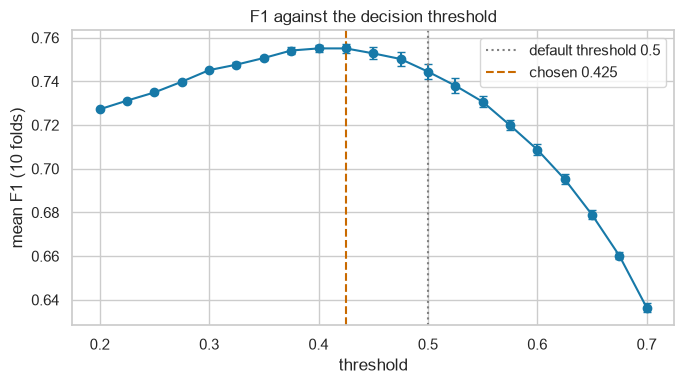

chosen threshold: 0.425
vs 0.5: {'dF1': np.float64(0.010624796458886998), 'SEM': np.float64(0.0016398617857768985), 'wins': '10/10', 'verdict': 'better'}
threshold 0.5: precision 0.7592, recall 0.7304, bal. acc. 0.7179, share predicted 'repeat' 0.539
threshold 0.425: precision 0.7115, recall 0.8045, bal. acc. 0.6949, share predicted 'repeat' 0.633


In [41]:
from sklearn.metrics import precision_score, recall_score

final_model = prepared(recipe_final, LogisticRegression(max_iter=1000))
thresholds = np.round(np.arange(0.20, 0.71, 0.025), 3)

fold_probabilities = []
for fit_at, score_at in folds:
    fitted = clone(final_model).fit(X_full.iloc[fit_at], y.iloc[fit_at])
    fold_probabilities.append((y.iloc[score_at].to_numpy(),
                               fitted.predict_proba(X_full.iloc[score_at])[:, 1]))

f1_by_threshold = pd.DataFrame(
    [[f1_score(truth, (prob >= t).astype(int)) for t in thresholds]
     for truth, prob in fold_probabilities], columns=thresholds)
mean_f1 = f1_by_threshold.mean().round(3)
tied = mean_f1.index[mean_f1 == mean_f1.max()]
THRESHOLD = float(min(tied, key=lambda t: abs(t - 0.5)))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(thresholds, f1_by_threshold.mean(), yerr=f1_by_threshold.sem(),
            marker="o", capsize=3, color=PLOT_BLUE)
ax.axvline(0.5, color="grey", linestyle=":", label="default threshold 0.5")
ax.axvline(THRESHOLD, color=PLOT_ORANGE, linestyle="--", label=f"chosen {THRESHOLD}")
ax.set(xlabel="threshold", ylabel="mean F1 (10 folds)", title="F1 against the decision threshold")
ax.legend()
plt.tight_layout()
plt.show()

print(f"chosen threshold: {THRESHOLD}")
print("vs 0.5:", paired_delta(f1_by_threshold[THRESHOLD], f1_by_threshold[0.5]))
for t in (0.5, THRESHOLD):
    labels = [(truth, (prob >= t).astype(int)) for truth, prob in fold_probabilities]
    print(f"threshold {t}: precision {np.mean([precision_score(a, b) for a, b in labels]):.4f},"
          f" recall {np.mean([recall_score(a, b) for a, b in labels]):.4f},"
          f" bal. acc. {np.mean([balanced_accuracy_score(a, b) for a, b in labels]):.4f},"
          f" share predicted 'repeat' {np.mean([b.mean() for _, b in labels]):.3f}")

<div class="alert alert-block alert-warning">

- A threshold of 0.425 raises F1 from 0.745 to 0.755 (+0.011 ± 0.0016, 10 of 10 folds);
- The model answers "repeat" for 63% of customers instead of 54%: recall 0.73 to 0.80, precision 0.76 to 0.71;
- Balanced accuracy falls from 0.718 to 0.695: it is a trade, chosen because the competition metric is F1.

</div>

40: Confirm on the time-ordered holdout.

In [42]:
recent = (train_fe["purchase_date"] >= pd.Timestamp("2024-01-01")).to_numpy()
X_past, y_past = X_full.loc[~recent], y.loc[~recent]
X_recent, y_recent = X_full.loc[recent], y.loc[recent]

past_folds = list(outer_splitter("classification", random_state=RANDOM_STATE).split(X_past, y_past))
past_probabilities = []
for fit_at, score_at in past_folds:
    fitted = clone(final_model).fit(X_past.iloc[fit_at], y_past.iloc[fit_at])
    past_probabilities.append((y_past.iloc[score_at].to_numpy(),
                               fitted.predict_proba(X_past.iloc[score_at])[:, 1]))
past_f1 = pd.Series({t: np.mean([f1_score(a, (p >= t).astype(int))
                                 for a, p in past_probabilities])
                     for t in thresholds}).round(3)
past_tied = past_f1.index[past_f1 == past_f1.max()]
past_threshold = float(min(past_tied, key=lambda t: abs(t - 0.5)))

recent_probability = clone(final_model).fit(X_past, y_past).predict_proba(X_recent)[:, 1]
print(f"threshold chosen on the past folds: {past_threshold}")
print(f"recent rows ({len(y_recent)}), repeat rate {y_recent.mean():.3f}")
print(f"  F1 at 0.5:              {f1_score(y_recent, (recent_probability >= 0.5).astype(int)):.4f}")
print(f"  F1 at {past_threshold}:            "
      f"{f1_score(y_recent, (recent_probability >= past_threshold).astype(int)):.4f}")
print(f"  floor (always repeat):  {f1_score(y_recent, np.ones(len(y_recent), dtype=int)):.4f}")
print(f"  ROC-AUC:                {roc_auc_score(y_recent, recent_probability):.4f}")

threshold chosen on the past folds: 0.4
recent rows (835), repeat rate 0.605
  F1 at 0.5:              0.7698
  F1 at 0.4:            0.7817
  floor (always repeat):  0.7537
  ROC-AUC:                0.7886


<div class="alert alert-block alert-warning">

- Using only the past, the procedure chooses a threshold of 0.40, next to the 0.425 chosen on all training rows;
- On the 2024-25 rows: F1 0.782 at 0.40, 0.770 at 0.5, 0.754 for the floor;
- ROC-AUC 0.789 is close to the cross-validated 0.788;
- The absolute F1 on Kaggle depends on the share of repeat purchases in test, which is unknown.

</div>

# <font color='#E8800A'>5. Predictions for file TEST</font> <a class="anchor" id="submission"></a>

41: Fit the final model on all training rows and save the submission.

In [43]:
deployed = clone(final_model).fit(X_full, y)
X_test_final = test_fe[recipe_final["categorical"] + recipe_final["numeric"]]
test_prediction = (deployed.predict_proba(X_test_final)[:, 1] >= THRESHOLD).astype(int)

submission = pd.DataFrame({"ID": X_test_final.index, TARGET: test_prediction})

assert len(submission) == len(sample) == 986
assert submission["ID"].is_unique
assert submission["ID"].tolist() == sample["ID"].tolist()
assert set(submission[TARGET].unique()) <= {0, 1}

submission.to_csv(DATA_DIR / "submission.csv", index=False)
print(f"columns kept by the selection: {len(deployed.named_steps['prep'].get_feature_names_out())}")
print(f"share predicted 'repeat' in test: {test_prediction.mean():.3f}")
print(submission.head())

columns kept by the selection: 33
share predicted 'repeat' in test: 0.706
         ID  repeat_purchase_90d
0  10000006                    1
1  10000008                    1
2  10000010                    1
3  10000020                    0
4  10000025                    0


<div class="alert alert-block alert-warning">

- Final pipeline: fixed rules → 11 candidate features → preprocessing pipeline (median / own level, `log1p`, target encoding, min-max, 2-of-3 vote; 33 columns kept when fitted on all training rows) → logistic regression → threshold 0.425;
- Cross-validated F1 0.755, ROC-AUC 0.788; time-ordered check F1 0.782;
- The test set only goes through `transform`, so no information from `test.csv` is used in any fit.

</div>